In [1]:
from selenium import webdriver
from selenium.webdriver.support.wait import WebDriverWait
from selenium.webdriver.support import expected_conditions
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.action_chains import ActionChains
from selenium.webdriver.support.ui import Select

import json, re, os, time
import pandas as pd
pd.options.display.max_columns=100

import pickle
import os
import sys
import warnings
import time

from bs4 import BeautifulSoup
import requests
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3'}
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36", "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8", "Accept-Language": "en-US,en;q=0.9", "Referer": "https://www.ewg.org/tapwater/", "Connection": "keep-alive"}



from selenium.webdriver.edge.options import Options

edge_options = Options()
#edge_options.add_argument('--headless')
edge_options.add_argument("--disable-images")  # Disable images
edge_options.add_argument("--disable-javascript")  # Disable JavaScript
edge_options.add_argument("--disable-plugins")  # Disable plugins
edge_options.add_argument("--disable-extensions")  # Disable extensions
edge_options.add_argument("--blink-settings=imagesEnabled=false")  # Another image disabling flag


# Set a minimal User-Agent (like a text-only browser)
edge_options.add_argument("user-agent=Links (2.25; Linux 2.4.24)")

driver = webdriver.Edge(options=edge_options)
#driver.execute_cdp_cmd("Network.setBlockedURLs", {"urls": ["*.jpg", "*.png", "*.gif","*.svg"]})
#driver.execute_cdp_cmd("Network.enable", {})


driver.maximize_window()

driver.execute_cdp_cmd("Network.enable", {})
driver.execute_cdp_cmd("Network.setBlockedURLs", {"urls": [
    "*.jpg", "*.png", "*.gif", "*.svg", "*.webp",
    "*.mp4", "*.webm", "*.m3u8",
    "*doubleclick.net*", "*googlesyndication.com*", "*googletagmanager.com*", "*adservice*"
]})

driver.execute_script("document.body.style.zoom='67%'")

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('ggplot')

### Scraping

In [ ]:
url='https://www.espn.com/mma/fightcenter/_/id/600057025/league/ufc'
driver.get(url)

In [ ]:
select_year_element=driver.find_elements(By.CSS_SELECTOR, 'div[class="MMAEventHeader__Event flex flex-column w-70"] select[class="dropdown__select"]')[0]
years_options=[e.text for e in select_year_element.find_elements(By.CSS_SELECTOR, 'option')]

In [ ]:
urls=[]

for years_option in years_options:
    try:
        Select(select_year_element).select_by_visible_text(years_option)
        time.sleep(2)
    except:
        continue
        
    try:
        select_event_element=driver.find_elements(By.CSS_SELECTOR, 'div[class="MMAEventHeader__Event flex flex-column w-70"] select[class="dropdown__select"]')[1]
        events_options=[e.text for e in select_event_element.find_elements(By.CSS_SELECTOR, 'option')]
    except:
        print('failed:', years_option, events_option, e)
        continue
        
    for events_option in events_options:
        try:
            Select(select_event_element).select_by_visible_text(events_option)
            time.sleep(2)
        except:
            continue

        url=driver.current_url
        dict_={'year':years_option, 'event':events_option, 'url':url}
        urls.append(dict_)

        print(f'{years_option} {events_option}', end='\r')
                

len(urls)

In [3]:
#pickle.dump(urls, open('event_urls.pickle','wb'))
urls=pickle.load( open('event_urls.pickle','rb'))

In [4]:
filtered_urls = []

for dict_ in urls:
    if (dict_['year'] != '2027'
        and 'Dana White' not in dict_['event']
        and 'Ultimate Fighter' not in dict_['event']):
        filtered_urls.append(dict_)

len(filtered_urls)

776

In [ ]:

CSV = "ufc_fights.csv"

def judge_points(det, side):
    """'45-50 | 45-50 | 45-50' -> this fighter's points per judge (awy = 1st number, hme = 2nd)."""
    pts = re.findall(r'(\d+)-(\d+)', det or '')
    out = [None, None, None]
    for k, (a, b) in enumerate(pts[:3]):
        out[k] = int(a) if side == 'awy' else int(b)
    return out

# resume from previous run
if os.path.exists(CSV):
    old = pd.read_csv(CSV, dtype={'event_id': str})
    rows = old.to_dict('records')
    scraped = set(old['event_id'].astype(str))
else:
    rows, scraped = [], set()

for i, dict_ in enumerate(filtered_urls, start=1):
    url = dict_['url']
    event_id = re.search(r'/id/(\d+)', url).group(1) 

    if event_id in scraped:
        print(f'{i}: skip {event_id}', end='\r')
        continue

    try:
        driver.get(url)
        time.sleep(1)
        html = driver.page_source

        m = re.search(r"window\['__espnfitt__'\]\s*=\s*(\{.*?\});</script>", html, re.S)
        data = json.loads(m.group(1))

        gp = data['page']['content']['gamepackage']
        hdr = gp['hdr']
        venue = hdr.get('venue', {})
        addr = venue.get('locAddr', {})

        event = {
            'event_id':   hdr['evt']['id'],
            'event_name': hdr['evt']['nm'],
            'event_date': hdr['evt']['dt'][:10],
            'venue':      venue.get('loc'),
            'city':       addr.get('city'),
            'state':      addr.get('state'),
            'country':    addr.get('country'),
        }

        new_rows = []
        for seg in gp['cardSegs']:
            for f in seg['mtchs']:
                for side in ('awy', 'hme'):
                    fighter = f[side]
                    opp = f['hme' if side == 'awy' else 'awy']
                    s = fighter['stats']
                    j1, j2, j3 = judge_points(f['dec'].get('det'), side)
                    new_rows.append({
                        **event,
                        'fight_id': f['id'],
                        'card': seg['hdr'],
                        'weight_class': f['nte'],
                        'fighter': fighter['dspNm'],
                        'nationality': fighter.get('country'),
                        'opponent': opp['dspNm'],
                        'opp_nationality': opp.get('country'),
                        'is_win': fighter['isWin'],
                        'method': f['dec']['shrtDspNm'],
                        'judge1_pts': j1, 'judge2_pts': j2, 'judge3_pts': j3,
                        'round': f['status']['rd'],
                        'time': f['status']['dspClk'],
                        'kd': s['kd'],
                        'sig_landed': s['sigstr']['val'], 'sig_att': s['sigstr']['tot'],
                        'tot_landed': s['totstr']['val'], 'tot_att': s['totstr']['tot'],
                        'head_landed': s['hd']['val'], 'head_att': s['hd']['tot'],
                        'body_landed': s['bdy']['val'], 'body_att': s['bdy']['tot'],
                        'leg_landed': s['lgs']['val'], 'leg_att': s['lgs']['tot'],
                        'td_landed': s['td']['val'], 'td_att': s['td']['tot'],
                        'sub_att': s['subatt'],
                        'control': s['ctrl'],
                    })

        rows += new_rows
        scraped.add(event_id)          
        pd.DataFrame(rows).to_csv(CSV, index=False)   
        print(f'{i}: done {event_id} ({len(new_rows)} rows)', end='\r')

    except Exception as e:
        print(f'{i}: failed {url} -> {e}') 

df = pd.DataFrame(rows)

In [5]:
df=pd.read_csv('ufc_fights.csv')

In [6]:
df

,event_id,event_name,event_date,venue,city,state,country,fight_id,card,weight_class,fighter,nationality,opponent,opp_nationality,is_win,method,judge1_pts,judge2_pts,judge3_pts,round,time,kd,sig_landed,sig_att,tot_landed,tot_att,head_landed,head_att,body_landed,body_att,leg_landed,leg_att,td_landed,td_att,sub_att,control
0,600057024,UFC 324: Gaethje vs. Pimblett,2026-01-24,T-Mobile Arena,Las Vegas,NV,USA,401836543,Main Card,Lightweight - Main Event - Title Fight,Justin Gaethje,USA,Paddy Pimblett,England,True,U Dec,48.0,49.0,49.0,R5,5:00,2,144,254,200,313,120,222,15,21,9,11,3,3,0,5:55
1,600057024,UFC 324: Gaethje vs. Pimblett,2026-01-24,T-Mobile Arena,Las Vegas,NV,USA,401836543,Main Card,Lightweight - Main Event - Title Fight,Paddy Pimblett,England,Justin Gaethje,USA,False,U Dec,47.0,46.0,46.0,R5,5:00,0,156,311,170,326,83,221,48,63,25,27,0,5,0,0:48
2,600057024,UFC 324: Gaethje vs. Pimblett,2026-01-24,T-Mobile Arena,Las Vegas,NV,USA,401836545,Main Card,Bantamweight,Sean O'Malley,USA,Song Yadong,China,True,U Dec,29.0,29.0,29.0,R3,5:00,0,48,92,67,111,23,53,16,28,9,11,0,0,0,0:00
3,600057024,UFC 324: Gaethje vs. Pimblett,2026-01-24,T-Mobile Arena,Las Vegas,NV,USA,401836545,Main Card,Bantamweight,Song Yadong,China,Sean O'Malley,USA,False,U Dec,28.0,28.0,28.0,R3,5:00,0,36,94,69,130,15,55,2,6,19,33,3,7,0,2:06
4,600057024,UFC 324: Gaethje vs. Pimblett,2026-01-24,T-Mobile Arena,Las Vegas,NV,USA,401836546,Main Card,Heavyweight,Waldo Cortes Acosta,Dominican Republic,Derrick Lewis,USA,True,KO/TKO,NaN,NaN,NaN,R2,3:14,1,44,62,46,64,35,53,5,5,4,4,1,1,0,0:28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17825,600002200,UFC Fight Night: Blaydes vs. Lewis,2021-02-20,Meta APEX,Las Vegas,NV,USA,401288354,Prelims,Women's Flyweight,Casey O'Neill,Australia,Shana Dobson,USA,True,KO/TKO,NaN,NaN,NaN,R2,3:41,0,49,68,132,183,44,62,3,4,2,2,4,6,1,7:26
17826,600002200,UFC Fight Night: Blaydes vs. Lewis,2021-02-20,Meta APEX,Las Vegas,NV,USA,401276257,Prelims,Bantamweight,Aiemann Zahabi,Canada,Drako Rodriguez,USA,True,KO/TKO,NaN,NaN,NaN,R1,3:05,1,9,11,9,11,8,10,1,1,0,0,0,0,0,0:10
17827,600002200,UFC Fight Night: Blaydes vs. Lewis,2021-02-20,Meta APEX,Las Vegas,NV,USA,401276257,Prelims,Bantamweight,Drako Rodriguez,USA,Aiemann Zahabi,Canada,False,KO/TKO,NaN,NaN,NaN,R1,3:05,0,11,33,13,35,6,27,1,2,4,4,0,0,0,0:00
17828,600002200,UFC Fight Night: Blaydes vs. Lewis,2021-02-20,Meta APEX,Las Vegas,NV,USA,401288356,Prelims,Heavyweight,Serghei Spivac,Moldova,Jared Vanderaa,USA,True,KO/TKO,NaN,NaN,NaN,R2,4:32,0,51,72,107,135,51,72,0,0,0,0,3,3,0,8:29


### EDA

In [7]:
df['control_sec']=df['control'].apply(lambda x:
                    int(x.split(':')[0])*60+int(x.split(':')[1])
                   )
df=df.drop(columns='control')

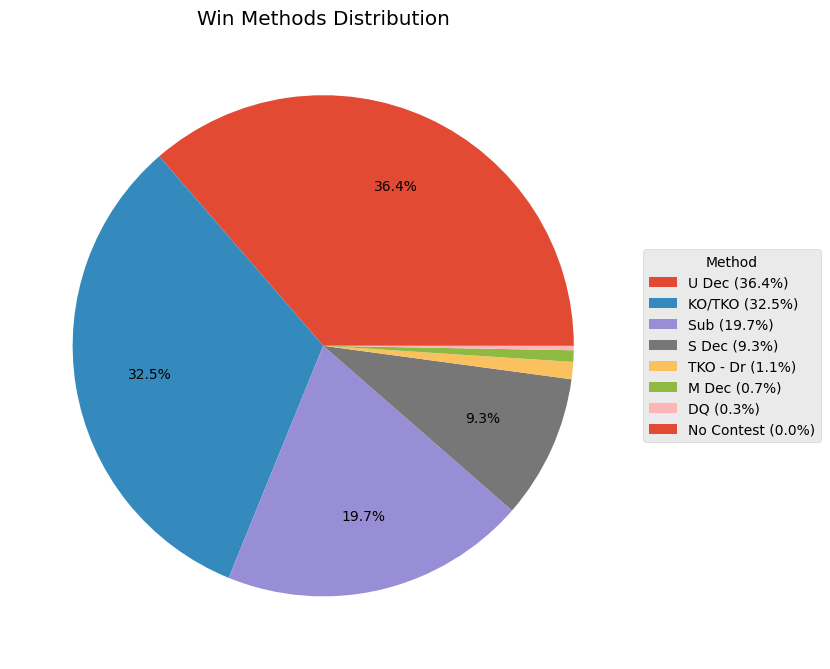

method
U Dec         36.35
KO/TKO        32.49
Sub           19.74
S Dec          9.28
TKO - Dr       1.11
M Dec          0.74
DQ             0.27
No Contest     0.01
Name: proportion, dtype: float64


In [8]:
counts = df.loc[df['is_win'], 'method'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(8, 7))

ax.pie(
    counts,
    labels=None,
    autopct=lambda p: f'{p:.1f}%' if p >= 5 else '',
    pctdistance=0.7,
    textprops={'fontsize': 10}
)

ax.legend(
    [f'{method} ({share:.1f}%)' for method, share in counts.items()],
    title='Method',
    loc='center left',
    bbox_to_anchor=(1, 0.5)
)

ax.set_title('Win Methods Distribution')
plt.tight_layout()
plt.show()

print(counts.round(2))

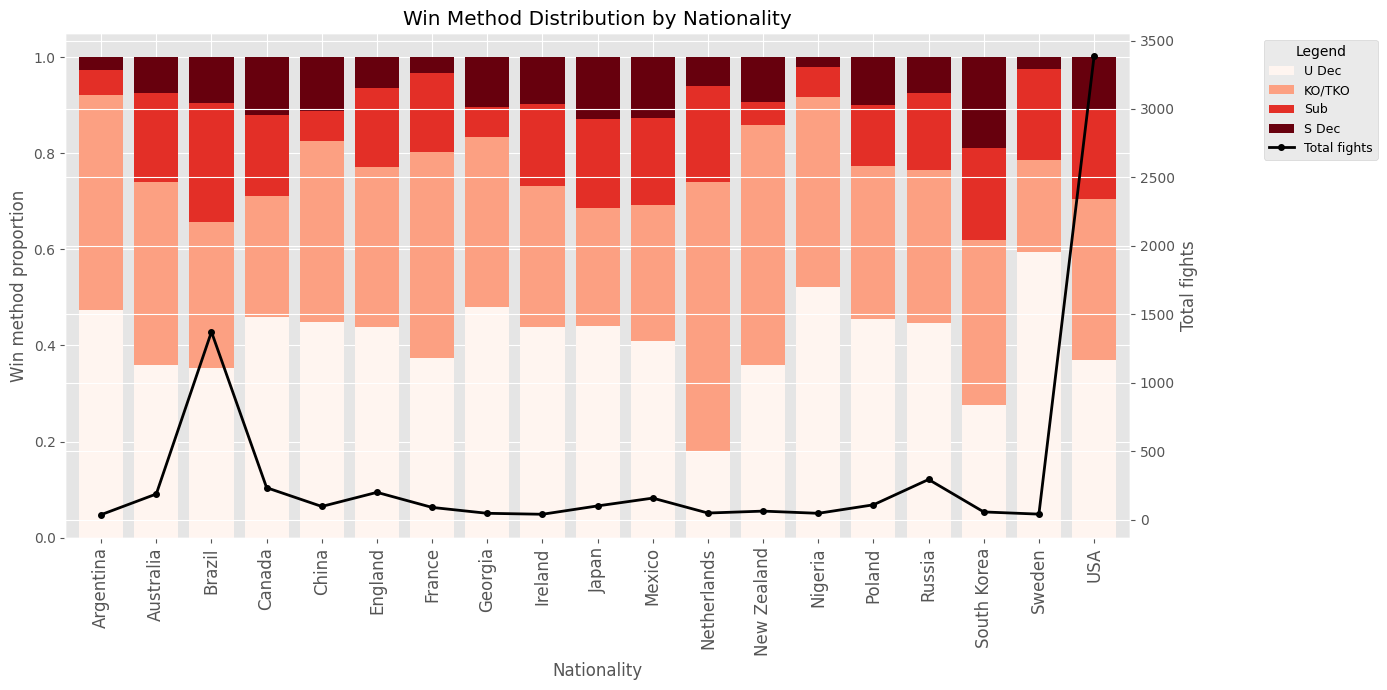

In [9]:
filtered = df[df['is_win'] == True]
filtered = filtered[filtered['method'].isin(['U Dec', 'KO/TKO', 'Sub', 'S Dec'])]

grouped = (
    filtered.groupby(['nationality', 'method'])['fight_id'].count()
    / filtered.groupby('nationality')['fight_id'].count()
).reset_index()

pivoted = grouped.pivot(index='nationality', columns='method', values='fight_id')

pivoted['Total fights'] = filtered.groupby('nationality')['fight_id'].count()

pivoted = pivoted[['U Dec', 'KO/TKO', 'Sub', 'S Dec', 'Total fights']]

pivoted=pivoted[pivoted['Total fights']>=35]


ax = pivoted[['U Dec', 'KO/TKO', 'Sub', 'S Dec']].plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    colormap='Reds',
    width=0.8
)

ax.set_xlabel('Nationality')
ax.set_ylabel('Win method proportion')
ax.tick_params(axis='x', labelrotation=45, labelsize=8)

ax2 = ax.twinx()
ax2.plot(
    ax.get_xticks(),
    pivoted['Total fights'],
    color='black',
    marker='o',
    linewidth=2,
    markersize=4,
    label='Total fights'
)

ax2.set_ylabel('Total fights')

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax.legend_.remove()

ax.legend(
    handles1 + handles2,
    labels1 + labels2,
    title='Legend',
    bbox_to_anchor=(1.12, 1),
    loc='upper left',
    fontsize=9,
    title_fontsize=10
)
ax.tick_params(axis='x', labelrotation=90, labelsize=12)

plt.title('Win Method Distribution by Nationality')
plt.tight_layout()
plt.show()

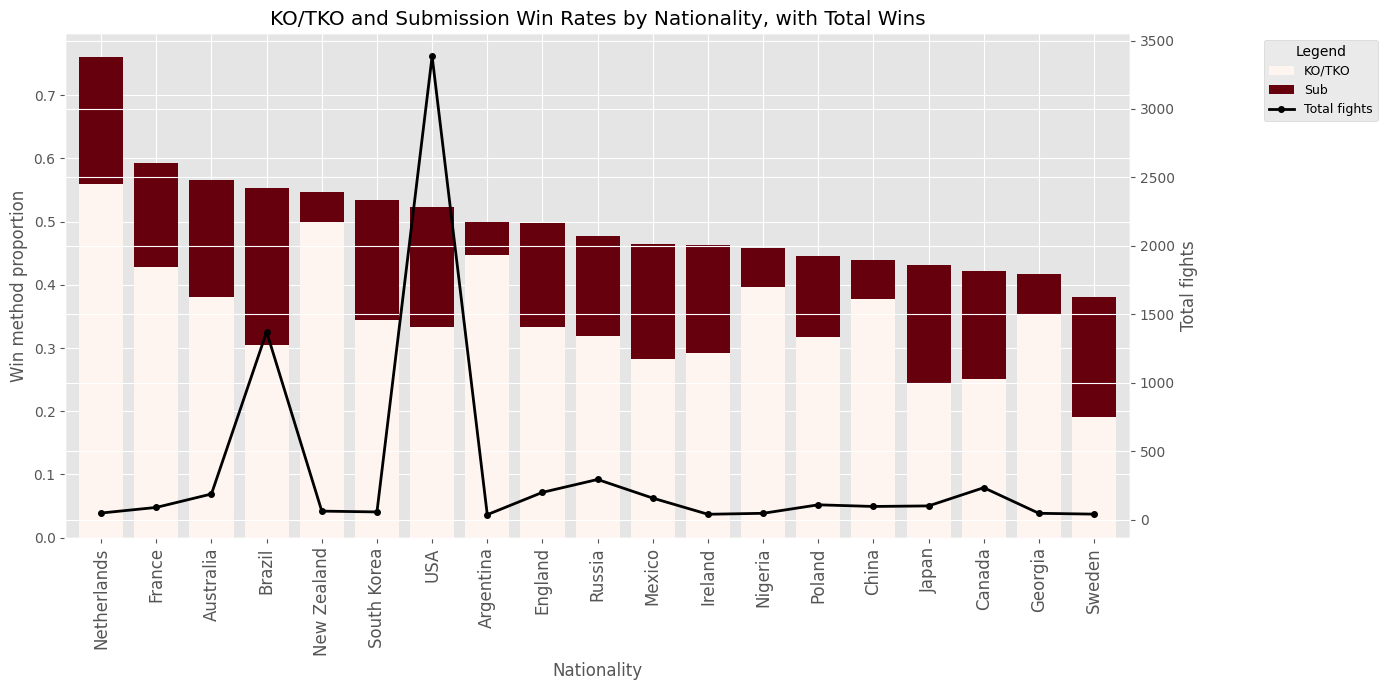

In [10]:
filtered = df[df['is_win'] == True]
filtered = filtered[filtered['method'].isin(['U Dec', 'KO/TKO', 'Sub', 'S Dec'])]

grouped = (
    filtered.groupby(['nationality', 'method'])['fight_id'].count()
    / filtered.groupby('nationality')['fight_id'].count()
).reset_index()

pivoted = grouped.pivot(index='nationality', columns='method', values='fight_id')

pivoted['Total fights'] = filtered.groupby('nationality')['fight_id'].count()

pivoted = pivoted[['U Dec', 'KO/TKO', 'Sub', 'S Dec', 'Total fights']]

pivoted=pivoted[pivoted['Total fights']>=35]
pivoted=pivoted.drop(columns=['U Dec', 'S Dec'])
pivoted = pivoted.loc[
    (pivoted['KO/TKO'] + pivoted['Sub']).sort_values(ascending=False).index
]


ax = pivoted[[ 'KO/TKO', 'Sub']].plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    colormap='Reds',
    width=0.8
)

ax.set_xlabel('Nationality')
ax.set_ylabel('Win method proportion')
ax.tick_params(axis='x', labelrotation=45, labelsize=8)

ax2 = ax.twinx()
ax2.plot(
    ax.get_xticks(),
    pivoted['Total fights'],
    color='black',
    marker='o',
    linewidth=2,
    markersize=4,
    label='Total fights'
)

ax2.set_ylabel('Total fights')

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax.legend_.remove()

ax.legend(
    handles1 + handles2,
    labels1 + labels2,
    title='Legend',
    bbox_to_anchor=(1.12, 1),
    loc='upper left',
    fontsize=9,
    title_fontsize=10
)
ax.tick_params(axis='x', labelrotation=90, labelsize=12)

plt.title('KO/TKO and Submission Win Rates by Nationality, with Total Wins')
plt.tight_layout()
plt.show()

In [11]:
# the Netherlands lead in TKO/KO/Submission win rates. This could be explained by following: 
#these finsih methods are most common in heavier weight classes, wehre one punch can decide the outcome of the fight
# Dutch are known to be bigger in size (in height and therefore in weight) and are mostly present in heavier weight classes
# also they are known to be good in kickboxing, not in grappling or wrestling
#below chart will display win methods rates by weight classes

In [12]:
df['weight_class']=df['weight_class'].apply(lambda x:x.split(' -')[0])
df['weight_class'] = df['weight_class'].replace([
    'Catch Weight',
    'Catchweight',
    'Open Weight',
    "Women's Catch Weight"
], None)

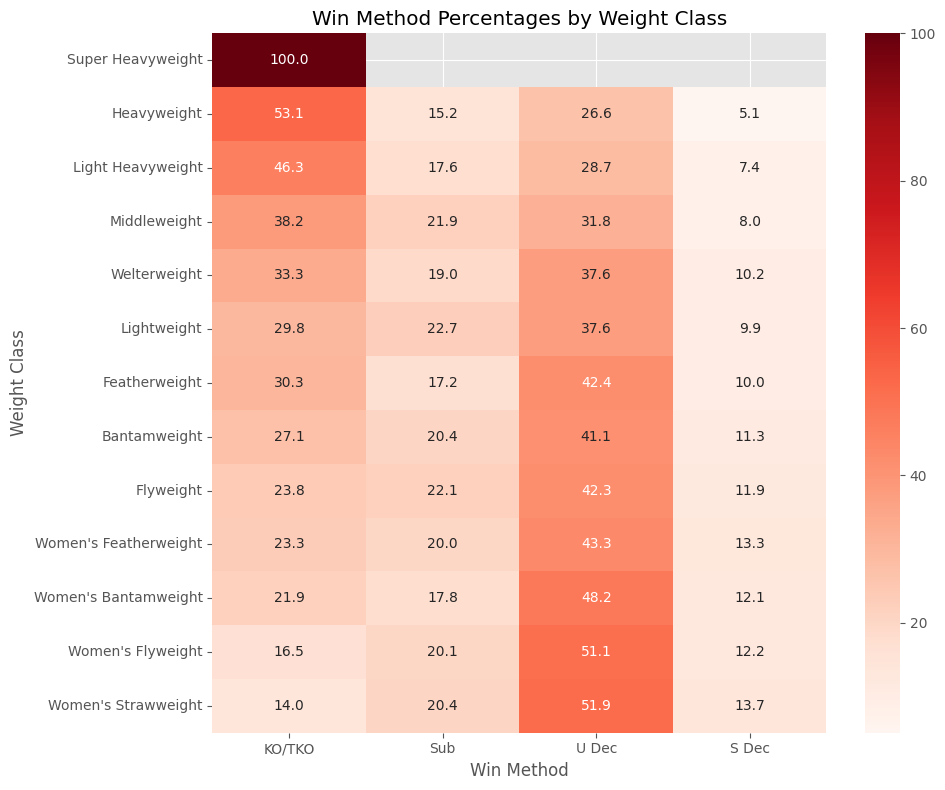

In [13]:
filtered = df[df['is_win'] == True]
filtered = filtered[filtered['method'].isin(['U Dec', 'KO/TKO', 'Sub', 'S Dec'])]

grouped = (
    filtered.groupby(['weight_class', 'method'])['fight_id'].count()
    / filtered.groupby('weight_class')['fight_id'].count()
).reset_index()

pivoted = grouped.pivot(
    index='weight_class',
    columns='method',
    values='fight_id'
) * 100

order = [
    "Women's Strawweight",
    "Women's Flyweight",
    "Women's Bantamweight",
    "Women's Featherweight",
    "Flyweight",
    "Bantamweight",
    "Featherweight",
    "Lightweight",
    "Welterweight",
    "Middleweight",
    "Light Heavyweight",
    "Heavyweight",
    "Super Heavyweight"
]

pivoted = pivoted.reindex(order[::-1])
pivoted=pivoted[['KO/TKO', 'Sub',  'U Dec','S Dec']]

plt.figure(figsize=(10, 8))
sns.heatmap(pivoted, annot=True, fmt='.1f', cmap='Reds')

plt.xlabel('Win Method')
plt.ylabel('Weight Class')
plt.title('Win Method Percentages by Weight Class')
plt.tight_layout()
plt.show()

### ML

In [14]:
filtered=df[df['method'].isin(['U Dec', 'S Dec'])]

columns=['event_id', 'event_name', 'event_date', 'venue', 'city', 'state', 'country', 'card', 'weight_class', 'nationality','opponent','opp_nationality','method', 'round', 'time', 'judge1_pts','judge2_pts','judge3_pts']
filtered=filtered.drop(columns=columns)

In [15]:
stats = filtered.drop(columns='is_win')

merged = filtered.merge(
    stats,
    on='fight_id',
    suffixes=('', '_opponent')
)

merged = merged[merged['fighter'] != merged['fighter_opponent']]
merged = merged.drop_duplicates(subset='fight_id')

merged=merged.drop(columns=['fight_id', 'fighter','fighter_opponent'])

In [16]:
merged

,is_win,kd,sig_landed,sig_att,tot_landed,tot_att,head_landed,head_att,body_landed,body_att,leg_landed,leg_att,td_landed,td_att,sub_att,control_sec,kd_opponent,sig_landed_opponent,sig_att_opponent,tot_landed_opponent,tot_att_opponent,head_landed_opponent,head_att_opponent,body_landed_opponent,body_att_opponent,leg_landed_opponent,leg_att_opponent,td_landed_opponent,td_att_opponent,sub_att_opponent,control_sec_opponent
1,True,2,144,254,200,313,120,222,15,21,9,11,3,3,0,355,0,156,311,170,326,83,221,48,63,25,27,0,5,0,48
5,True,0,48,92,67,111,23,53,16,28,9,11,0,0,0,0,0,36,94,69,130,15,55,2,6,19,33,3,7,0,126
9,True,0,51,133,63,147,25,95,8,14,18,24,1,2,0,84,0,26,94,46,119,11,64,3,13,12,17,1,5,0,129
13,False,0,56,116,60,121,37,86,11,22,8,8,0,0,0,54,0,74,136,78,141,43,103,22,23,9,10,4,6,0,32
17,True,0,34,72,103,167,19,50,11,17,4,5,2,6,0,290,0,8,27,28,58,4,18,4,8,0,1,0,0,0,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15969,False,0,59,120,62,124,15,56,28,40,16,24,1,1,1,9,1,69,126,72,131,23,59,14,21,32,46,1,1,0,71
15973,True,2,70,152,128,213,36,112,15,20,19,20,2,2,1,193,0,42,86,48,93,25,67,8,10,9,9,2,6,0,343
15977,False,0,7,16,35,51,3,10,3,4,1,2,3,8,0,518,0,47,60,215,247,7,15,30,35,10,10,0,0,0,309
15981,False,0,15,25,40,51,9,17,4,4,2,4,0,1,2,0,1,45,60,96,117,35,49,5,5,5,6,4,5,3,754


Fitting 5 folds for each of 64 candidates, totalling 320 fits
Best parameters:
{'xgb__colsample_bytree': 1.0, 'xgb__learning_rate': 0.03, 'xgb__max_depth': 5, 'xgb__min_child_weight': 1, 'xgb__n_estimators': 300, 'xgb__subsample': 0.8}

Best CV accuracy: 0.8342

Test accuracy: 0.8375
Test ROC-AUC: 0.9197

Classification report:
              precision    recall  f1-score   support

           0       0.83      0.78      0.80       340
           1       0.84      0.88      0.86       460

    accuracy                           0.84       800
   macro avg       0.84      0.83      0.83       800
weighted avg       0.84      0.84      0.84       800



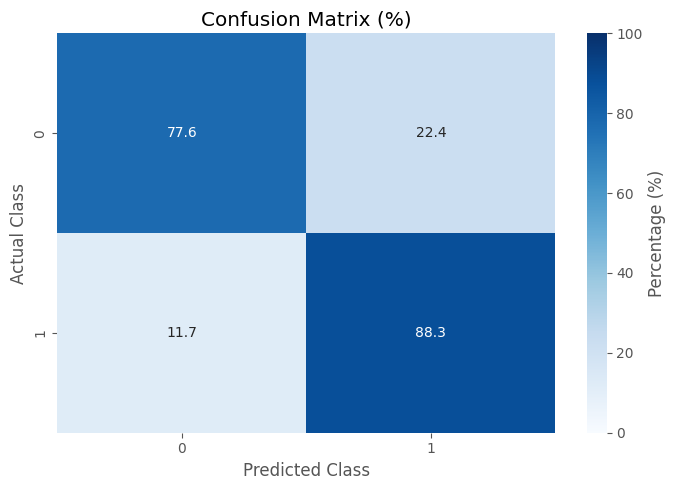


Top 15 features:
tot_landed_opponent     0.124155
tot_landed              0.113010
td_landed_opponent      0.060266
td_landed               0.059491
head_landed             0.050226
head_landed_opponent    0.050160
sig_landed_opponent     0.043713
sig_landed              0.038090
kd                      0.035191
kd_opponent             0.033355
control_sec             0.032115
control_sec_opponent    0.026786
sub_att                 0.022076
head_att                0.021713
sig_att_opponent        0.021519
dtype: float32


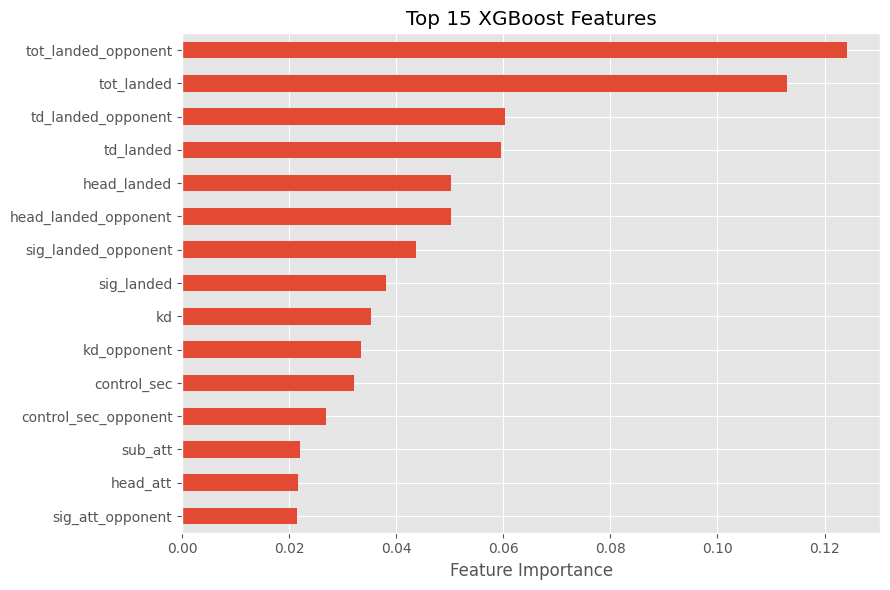

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 1. Prepare the data
data = merged.copy()

drop_cols = [
    'is_win',
    'is_win_opponent',
    'fight_id',
    'fighter',
    'fighter_opponent',
    'method',
    'method_opponent',
    'event_id',
    'event',
    'event_date'
]

X = data.drop(columns=drop_cols, errors='ignore')
y = data['is_win'].astype(int)

# Use numeric features
X = X.select_dtypes(include='number')

# Remove any remaining target leakage columns
X = X.loc[:, ~X.columns.str.contains(
    r'^is_win|winner|outcome|result',
    case=False,
    regex=True
)]

# 2. Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Build the pipeline
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('xgb', XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        n_jobs=1
    ))
])

# 4. Define the parameter grid
param_grid = {
    'xgb__n_estimators': [150, 300],
    'xgb__max_depth': [3, 5],
    'xgb__learning_rate': [0.03, 0.1],
    'xgb__min_child_weight': [1, 5],
    'xgb__subsample': [0.8, 1.0],
    'xgb__colsample_bytree': [0.8, 1.0]
}
# 5. Configure cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# 6. Train and tune
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print('Best parameters:')
print(grid_search.best_params_)

print(f'\nBest CV accuracy: {grid_search.best_score_:.4f}')

# 7. Evaluate on the untouched test set
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(f'\nTest accuracy: {accuracy_score(y_test, y_pred):.4f}')
print(f'Test ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}')

print('\nClassification report:')
print(classification_report(y_test, y_pred))

# 8. Confusion matrix
cm = confusion_matrix(y_test, y_pred, normalize='true') * 100

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    xticklabels=[0, 1],
    yticklabels=[0, 1],
    vmin=0,
    vmax=100,
    cbar_kws={'label': 'Percentage (%)'}
)

plt.title('Confusion Matrix (%)')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.tight_layout()
plt.show()

# 9. Feature importance
importance = pd.Series(
    best_model.named_steps['xgb'].feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print('\nTop 15 features:')
print(importance.head(15))

importance.head(15).sort_values().plot(
    kind='barh',
    figsize=(9, 6)
)
plt.xlabel('Feature Importance')
plt.title('Top 15 XGBoost Features')
plt.tight_layout()
plt.show()
